# Audio Analyzer

This notebook allows to analyze any given audio using different functions such as spectogram, spectrum and filters.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal
from scipy.fft import fft
import IPython.display as ipd
from scipy.io.wavfile import read
from pydub import AudioSegment

In [ ]:
# functions used in the whole lab
def read_sound(file):
  """ read a mono wav sound file, assuming is mono, and convert it to a floating point array
    Args:
      file (str): File name
    Returns:
      sound_array (numpy.array): Array of samples as floating point values between -1 and 1
      sampling_rate (int): Sampling rate
  """
  # read sound file
  sampling_rate, x = read(file)
  # convert to floating point values between -1 and 1, assuming x are 16 bit integers
  sound_array = np.float32(x) / 2**15
  return sound_array, sampling_rate

def display_sound(sound_array, sampling_rate=44100):
  """ Display signal sound_array
    Args:
      sound_array (numpy.array): Array of samples
      sampling_rate (int): Sampling rate
  """
  # plot the waveform of the sound
  plt.figure(0, figsize=(10, 3))
  time_indexes = np.arange(0, sound_array.size/sampling_rate, 1.0/sampling_rate)
  plt.plot(time_indexes, sound_array)
  plt.xlabel('time (seconds)')
  plt.ylabel('amplitude')
  plt.show()
  # play the sound
  ipd.display(ipd.Audio(data=sound_array, rate=sampling_rate))

def display_spectrum(sound_array, sampling_rate=44100):
  """ Display magnitude spectrum of signal sound_array
    Args:
      sound_array (numpy.array): Array of samples
      sampling_rate (int): Sampling rate
  """
  # compute the hanning window
  window = signal.get_window('hann', sound_array.size)
  # compute the spectrum of the windowed input signal
  spectrum = fft(window*sound_array)
  # compute the magnitude spectrum in dB
  magnitude_spectrum = 20*np.log10(abs(spectrum[:spectrum.size//2]))

  # plot the magnitude spectrum
  plt.figure(0, figsize=(10, 5))
  frequency_indexes = np.arange(0, sampling_rate/2, sampling_rate/spectrum.size)
  plt.plot(frequency_indexes, magnitude_spectrum)
  plt.xlabel('frequency (Hz)')
  plt.ylabel('amplitude (dB)')
  plt.show()

def display_spectrogram(sound_array, hop_size=256, fft_size=512, sampling_rate=44100):
  """ Display magnitude spectrogram of signal sound_array
    Args:
      sound_array (numpy.array): Array of samples
      hop_size (int): window hop size
      fft_size (int): Spectrogram fft size
      sampling_rate (int): Sampling rate of sound
  """
  # compute the hanning window
  window = signal.get_window('hann', fft_size)
  # initialize the output spectrogram
  magnitude_spectrogram = []
  sample_index = 0
  # iterate over the input sound computing a sequence of spectra
  while sample_index < sound_array.size-fft_size:
    spectrum = fft(window*sound_array[sample_index:sample_index+fft_size])
    magnitude_spectrum = 20*np.log10(abs(spectrum[:spectrum.size//2]))
    magnitude_spectrogram.append(magnitude_spectrum)
    sample_index += hop_size

  # plot the magnitude spectrogram
  plt.figure(figsize=(10, 5))
  time_indexes = np.arange(0, sample_index/sampling_rate, hop_size/sampling_rate)
  frequency_indexes = np.arange(0, sampling_rate/2, sampling_rate/fft_size)
  plt.pcolormesh(time_indexes, frequency_indexes, np.transpose(magnitude_spectrogram), shading='nearest', cmap='inferno')
  plt.colorbar(format='%+2.0f dB')
  plt.xlabel('time (seconds)')
  plt.ylabel('frequency (Hz)')
  plt.show()



  def plot_freq_response(w, h, title):
  "Utility function to plot frequency response functions"
  fig = plt.figure(figsize=(10, 5))
  ax = fig.add_subplot(111)
  ax.plot(w, 20*np.log10(np.abs(h)))
  ax.set_ylim(-80, 5)
  ax.grid(True)
  ax.set_xlabel('Frequency (Hz)')
  ax.set_ylabel('Gain (dB)')
  ax.set_title(title)

def prototype_filter(N, L):
  """ Generate a prototype FIR low-pass filter using a window method.
    Args:
      N (int): length of filter
      L (int): number of subbands
    Returns:
      Coefficients of the resulting FIR filter
  """
  return signal.firwin(N, 1.0 / (2 * L), window='hamming')

def modulate_filter(h, M, k):
    # Modulate the prototype filter
    n = np.arange(len(h))
    modulation = 2 * np.cos(np.pi * (2 * k + 1) * (n - (len(h) - 1) / 2) / (2 * M))
    return h * modulation

def analysis_filter_bank(x, M, N):
    # Analysis Filter Bank using Polyphase Decomposition
    h = prototype_filter(N, M)
    subband_length = len(x) // M
    subbands = np.zeros((M, subband_length))

    for k in range(M):
        hk = modulate_filter(h, M, k)
        filtered_signal = signal.lfilter(hk, 1.0, x)
        # Ensure the subband length matches the expected size
        downsampled_signal = filtered_signal[::M]
        if len(downsampled_signal) > subband_length:
            subbands[k] = downsampled_signal[:subband_length]
        else:
            subbands[k, :len(downsampled_signal)] = downsampled_signal

    return subbands

def synthesis_filter_bank(subbands, M, N):
    # Synthesis Filter Bank using Polyphase Decomposition
    h = prototype_filter(N, M)
    y_reconstructed = np.zeros(M * len(subbands[0]))

    for k in range(M):
        hk = modulate_filter(h, M, k)
        upsampled_signal = np.zeros(len(y_reconstructed))
        upsampled_signal[::M] = subbands[k]  # Upsample by M
        y_reconstructed += signal.lfilter(hk, 1.0, upsampled_signal)

    return y_reconstructed

## Part 1- Reading and plotting an audio file

Read and plot an audio file from the 'sounds' directory. Listen to the sound and plot its waveform, plot the magnitude spectrogram of the whole sound. For both the spectrum and the spectrogram try different values of the `fft_size`: 256, 1024, and 2048. Answer the questions given and modify the code to support your answers.

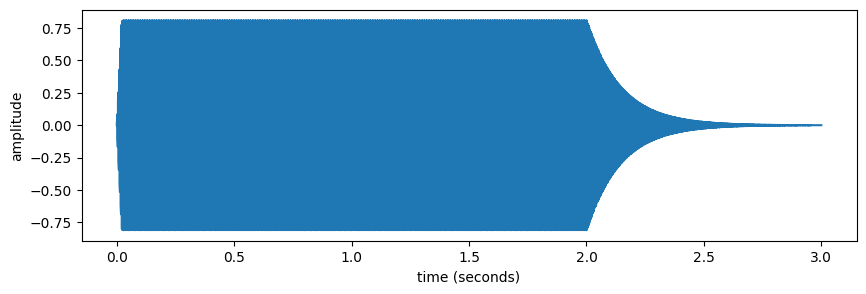

In [4]:
# read and display a sound
sound_array, sampling_rate = read_sound('../sounds/synthetic.wav')
display_sound(sound_array, sampling_rate)

FFT size of 256


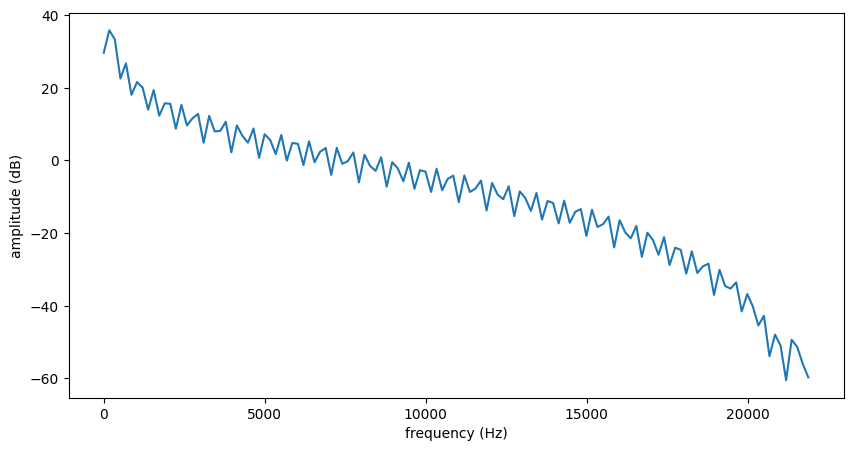

FFT size of 1024


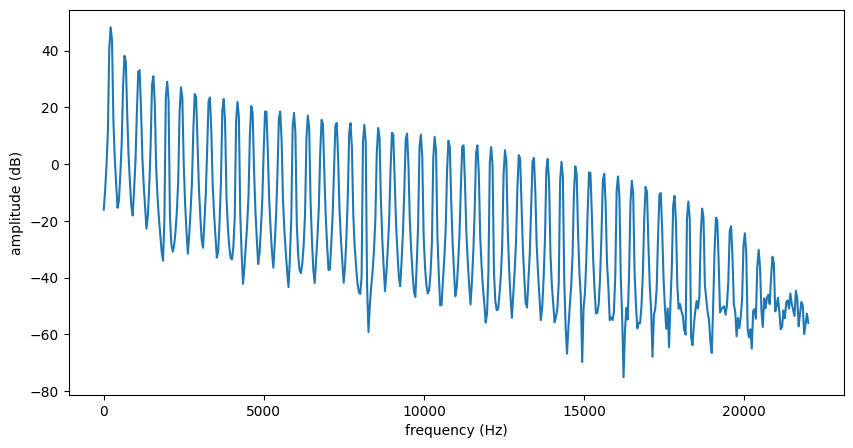

FFT size of 2048


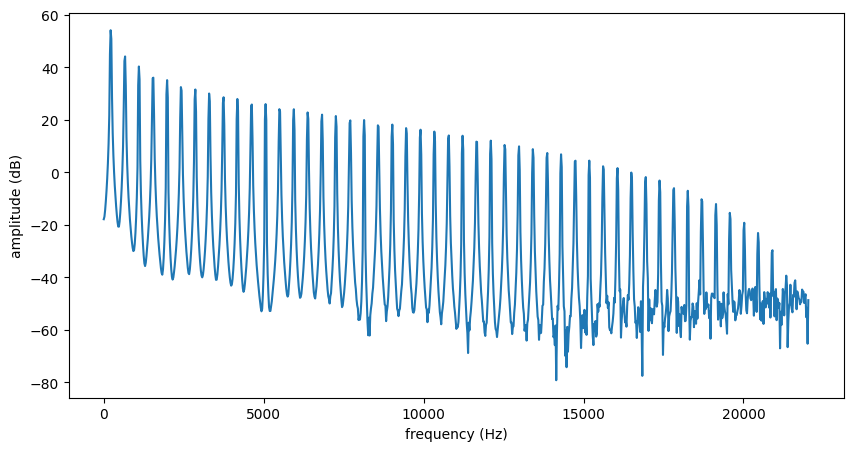

In [5]:
# display spectrum of a stable fragment of sound_array, try different values for fft_size, all being a power of 2
# ex: 256, 1024, 2048
fft_sizes = [256, 1024, 2048]


sample_offset = int(1.0 * sampling_rate) # choose the starting sample at 1 second
for size in fft_sizes:
    print(f'FFT size of', size)
    display_spectrum(sound_array[sample_offset:sample_offset+size], sampling_rate)
    




FFT size of 256


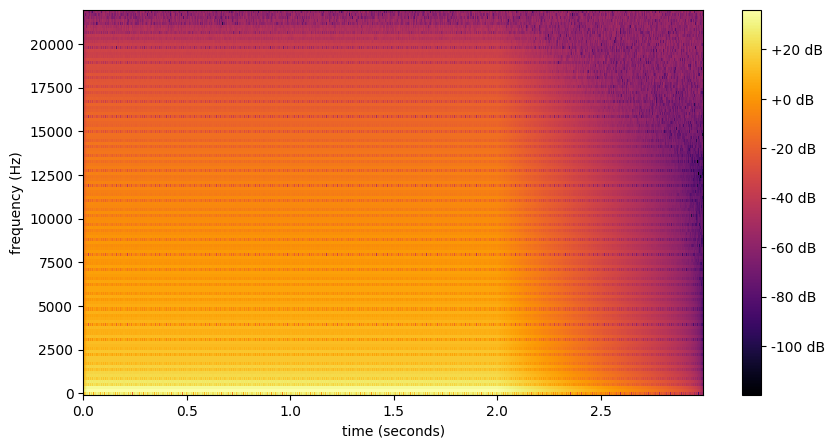

FFT size of 1024


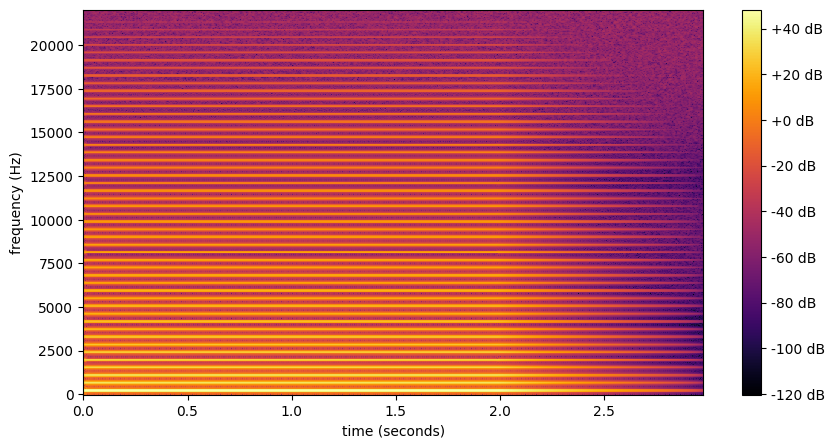

FFT size of 2048


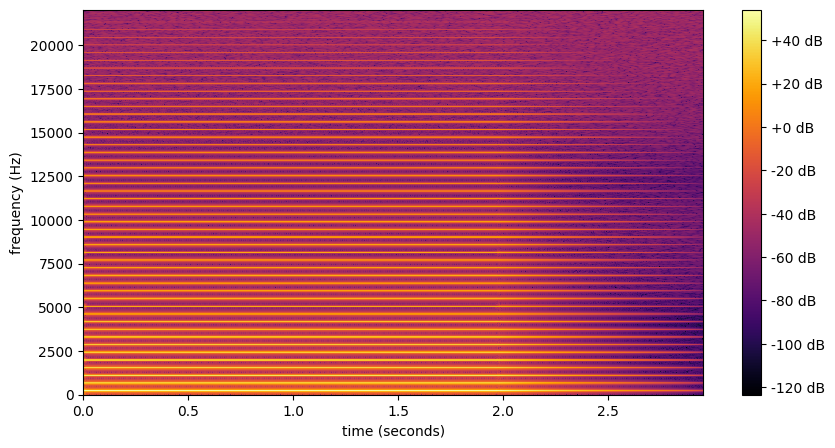

In [6]:
# display spectrogram of x, try different values for fft_size, all being a power of 2
# ex: 256, 1024, 2048
hop_size = 128
fft_sizes = [256, 1024, 2048]
for size in fft_sizes:
    print(f'FFT size of', size)
    display_spectrogram(sound_array, hop_size, size, sampling_rate)

## Part 2 - Finding the maximum frequency

In [11]:
## Finding the highest frequency of the signal
def maximum_frequency(sound_array, sampling_rate=44100):
    window = signal.get_window('hann', sound_array.size)
    spectrum = fft(window*sound_array)
    magnitude_spectrum = 20*np.log10(abs(spectrum[:spectrum.size//2]))
    frequency_indexes = np.arange(0, sampling_rate/2, sampling_rate/spectrum.size)

    i = 0
    index = 0
    while i<len(magnitude_spectrum):
        if magnitude_spectrum[i] > -40:
            index = i
        else:
            index = index
        i = i+1
    fmax = frequency_indexes[index]
    
    return fmax

In [12]:
fmax = maximum_frequency(sound_array,sampling_rate=44100)
print("The maximum frequency of the signal is", round(fmax,2), "Hz.")

The maximum frequency of the signal is 22049.67 Hz.


## Part 3- Low-Pass Filter (LPF)

Designed a low-pass filter using the window method, `firwin` algorithm, you can filter a sound with it.

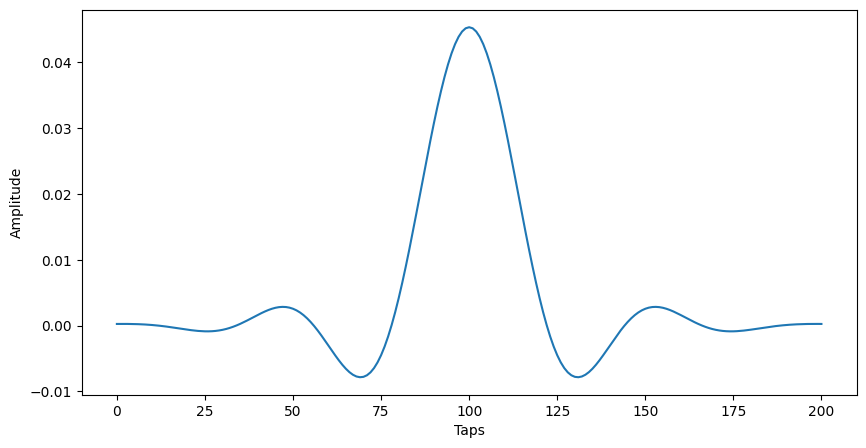

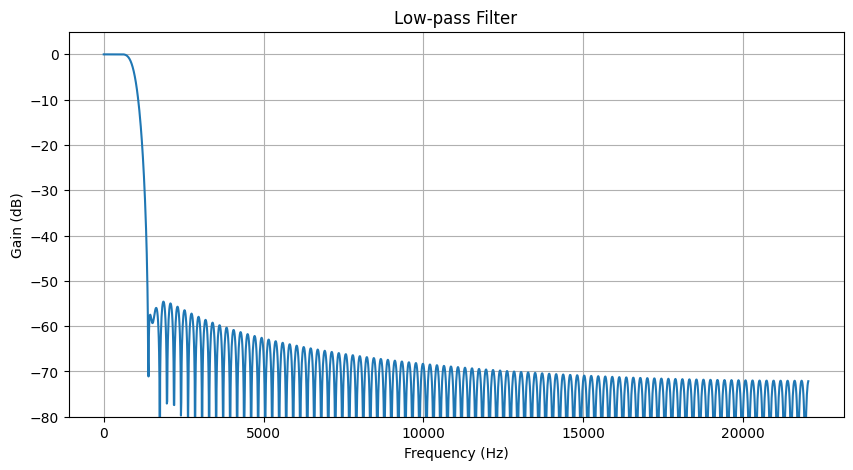

In [ ]:
# DESIGNING THE LOW-PASS FILTER AND SHOWING THE IMPULSE AND FREQUENCY RESPONSE

# Step 01: Design
fs = 44100.0
filter_lengths = [8,800,8000]
cutoff = 1000
h_tot = []
for filter_length in filter_lengths:

    h = signal.firwin(filter_length, cutoff, window='hamming', fs=fs)
    h_tot.append(h)

    # Step 02: Showing Impulse Response
    plt.figure(figsize=(10, 5))
    plt.plot(h)
    plt.title(f"Impulse response with filter length {filter_length}")
    plt.xlabel('Taps')
    plt.ylabel('Amplitude')
    plt.show()

    # Step 03: Showing frequency response
    w, H = signal.freqz(h, [1], worN=2000, fs=fs)
    plot_freq_response(w, H, f"Low-pass Filter with filter length {filter_length}")
    plt.show()

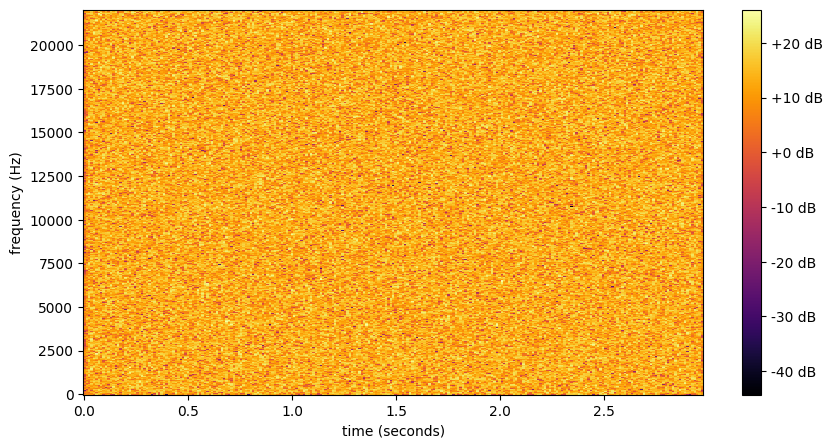

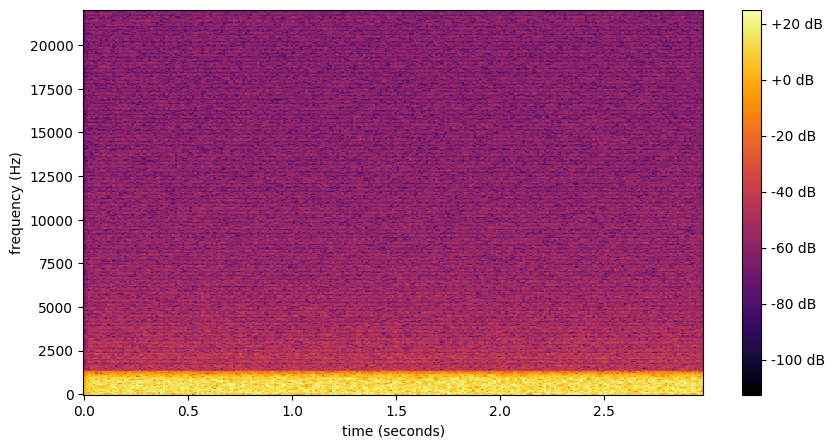

In [ ]:
## FILTERING THE  SOUND WITH THE PREVIOUS LPFs

# Step 01: Read the sound
sound_array, sampling_rate = read_sound('../sounds/white-noise.wav')

# Step 02: Display the original white-noise sound
print(" Original White Noise Sound")
ipd.display(ipd.Audio(data=sound_array, rate=sampling_rate))
print("Spectogram of original White Noise Sound")
display_spectrogram(sound_array, 512, 1024, sampling_rate)

# Step 03: Apply filter by convolving the sound with the impulse response of filter
for h, filter_length in zip(h_tot, filter_lengths):
    filtered_sound = signal.lfilter(h, 1, sound_array)

    # Step 04: Display the filtered white-noise sound
    print("Filtered White Noise sound with LPF length", filter_length )
    ipd.display(ipd.Audio(data=filtered_sound, rate=sampling_rate))
    print("Spectogram of filtered White Noise sound with LPF length", filter_length)
    display_spectrogram(filtered_sound, 512, 1024, sampling_rate)

## Part 3- Band-Pass Filter (BPF)

Designed a band-pass filter using a Low-Pass Filter, `firwin` algorithm, you can filter a sound with it.

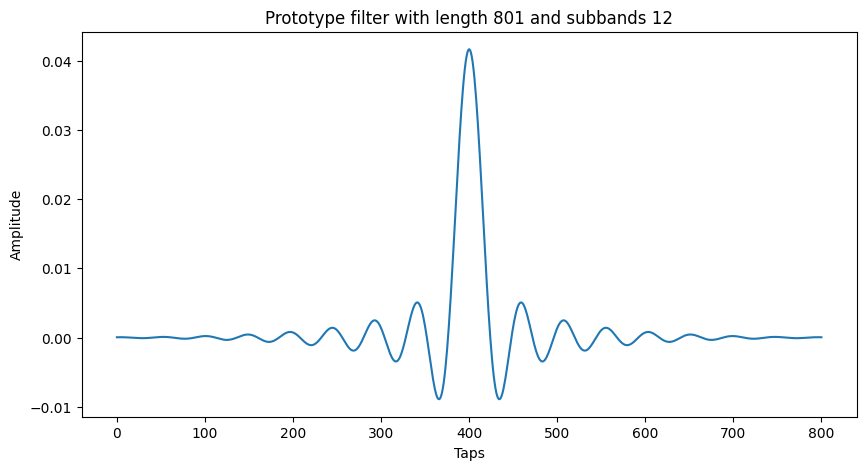

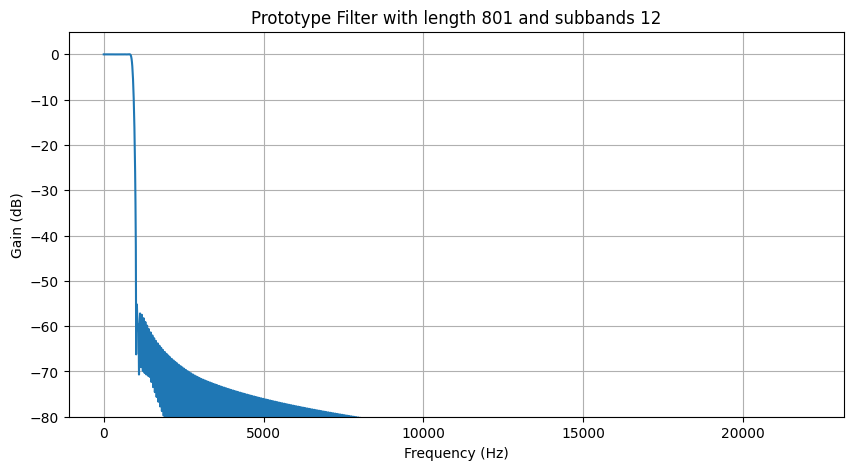

<Figure size 1000x500 with 0 Axes>

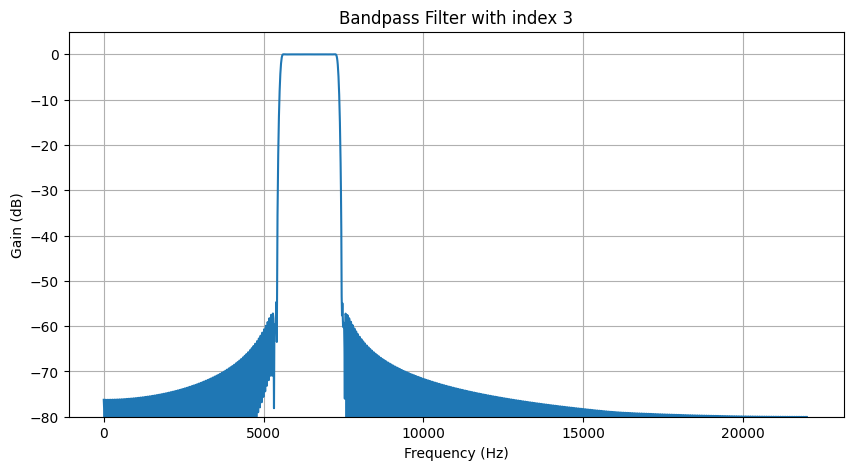

In [ ]:
## IMPLEMENTING A LPF AND CONVERTING IT TO A BPF

# Step 01: Defining the Parameters for the filter bank
N = 801 
L = 12   
fs = 44100  

# Step 02: Generating  the prototype filter
h = prototype_filter(N, L)

# Step 03: Ploting the prototype filter
plt.figure(figsize=(10, 5))
plt.plot(h)
plt.xlabel('Taps')
plt.ylabel('Amplitude')
plt.title(f"Prototype filter with length {N} and subbands {L}")
plt.show()

# Step 04: Plotting the frequency response of the prototype filter
w, H = signal.freqz(h, [1], worN=2000, fs=fs)
plot_freq_response(w, H, f"Prototype Filter with length {N} and subbands {L}")
plt.show()


# Step 05: Creating the bandpass filter
k = 3 
hk = modulate_filter(h, L, k)

# Step 06: Plotting the frequency response of the bandpass filter
plt.figure(figsize=(10, 5))
w, H = signal.freqz(hk, [1], worN=2000, fs=fs)
plot_freq_response(w, H, f"Bandpass Filter with index {k}")
plt.show()

Spectogram of filtered sound TRUMPET with BPF of index 3


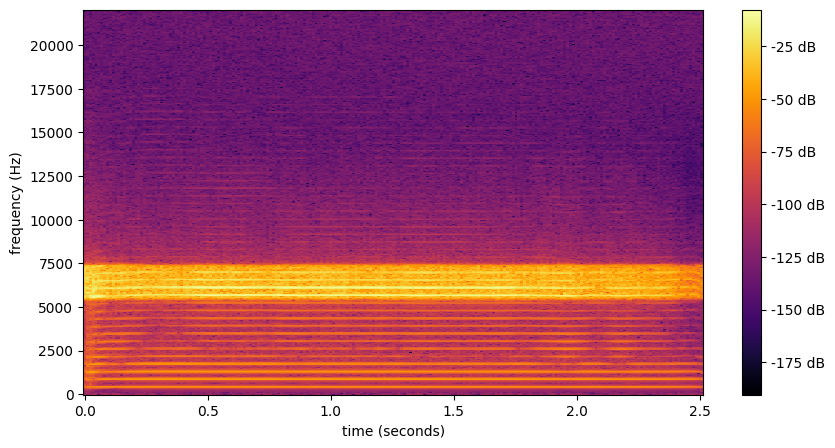

In [ ]:
## APPLYING THE BPF CREATED TO THE SOUND TRUMPET

#Step 01: Reading the sound TRUMPET
sound_array, sampling_rate = read_sound('../sounds/487465-trumpet.wav')

# Step 02: Filtering the sound TRUMPET by convolving it with the IR of the filter
filtered_sound = signal.lfilter(hk, 1, sound_array)

# Step 03: Displaying the audio and spectogram of the filtered sound

ipd.display(ipd.Audio(data=filtered_sound, rate=sampling_rate))
print(f"Spectogram of filtered sound TRUMPET with BPF of index {k}")
display_spectrogram(filtered_sound, 512, 1024, sampling_rate)

## Part 4- High-Pass Filter (HPF)

Designed a high-pass filter using the window method, `firwin` algorithm, you can filter a sound with it.

In [ ]:
# DESIGNING THE HIGH-PASS FILTER AND SHOWING THE IMPULSE AND FREQUENCY RESPONSE

# Step 01: Design
fs = 44100.0
filter_lengths = [8,800,8000]
cutoff = 10000
h_tot = []
for filter_length in filter_lengths:

    h = signal.firwin(filter_length, cutoff, window='hamming', fs=fs)
    h_tot.append(h)

    # Step 02: Showing Impulse Response
    plt.figure(figsize=(10, 5))
    plt.plot(h)
    plt.title(f"Impulse response with filter length {filter_length}")
    plt.xlabel('Taps')
    plt.ylabel('Amplitude')
    plt.show()

    # Step 03: Showing frequency response
    w, H = signal.freqz(h, [1], worN=2000, fs=fs)
    plot_freq_response(w, H, f"Low-pass Filter with filter length {filter_length}")
    plt.show()